# 05 · Going 2D: transport of a contaminant in a stirred tank
**Level: Advanced** · ~15 min · *Track: 2D fields*

The 2D track models a **contaminant concentration** $c(x,y,t)$ in a stirred water tank (or a
ventilated room). Three processes compete:

$$\frac{\partial c}{\partial t} + \underbrace{a\,\mathbf{v}\cdot\nabla c}_{\text{advection}} = \underbrace{\kappa\,\nabla^2 c}_{\text{diffusion}} - \underbrace{\lambda c}_{\text{decay}} + \underbrace{s(x,y,t)}_{\text{source}}$$

* $\mathbf v$: a stirring flow (here a closed vortex, so nothing leaves through the walls)
* $a$: flow strength (pump speed), $\kappa$: diffusivity, $\lambda$: decay / removal rate

Their balance is the **Péclet number** $\mathrm{Pe} = UL/\kappa$: low Pe means diffusion wins
(smooth blobs), high Pe means advection wins (thin filaments, sharp fronts that are hard for
sensors and models alike).

**You will learn**
* the `AdvDiff2D` solver (finite volumes, upwind advection, batched over ensembles)
* how to visualise 2D fields over time: snapshot grids, animations, probe time series, streamlines
* how Pe controls the field's structure and what the solver's numerical diffusion does

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML
from dtwin import viz
from dtwin.solvers import AdvDiff2D, gaussian_blob
viz.set_style()

## 1. The stirring flow
A **cellular flow** from the stream function $\psi = \sin(\pi x)\sin(\pi y)$, with velocity
$(u, v) = (\partial_y\psi, -\partial_x\psi)$. It is divergence-free (incompressible) and has zero
normal velocity at the walls.

grid 96x96, dt = 0.0136, max speed = 0.063, Pe = 63


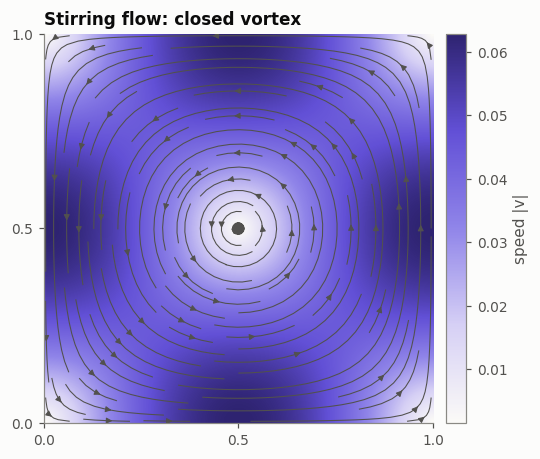

In [2]:
tank = AdvDiff2D(n=96, kappa=1e-3, flow_amplitude=0.02)
X, Y = tank.X, tank.Y
speed = tank.flow_amplitude * np.hypot(tank.U, tank.V)
print(f"grid {tank.n}x{tank.n}, dt = {tank.dt:.4f}, max speed = {speed.max():.3f}, "
      f"Pe = {speed.max() * 1.0 / tank.kappa:.0f}")

fig, ax = plt.subplots(figsize=(5.2, 4.6))
viz.field(ax, speed, cmap=viz.UNCERTAINTY, label="speed |v|", title="Stirring flow: closed vortex")
ax.streamplot(tank.x, tank.x, tank.U, tank.V, color=viz.INK2, density=1.1, linewidth=0.7, arrowsize=0.8)
plt.show()

## 2. Diffusion vs. advection: the same blob, three Péclet numbers

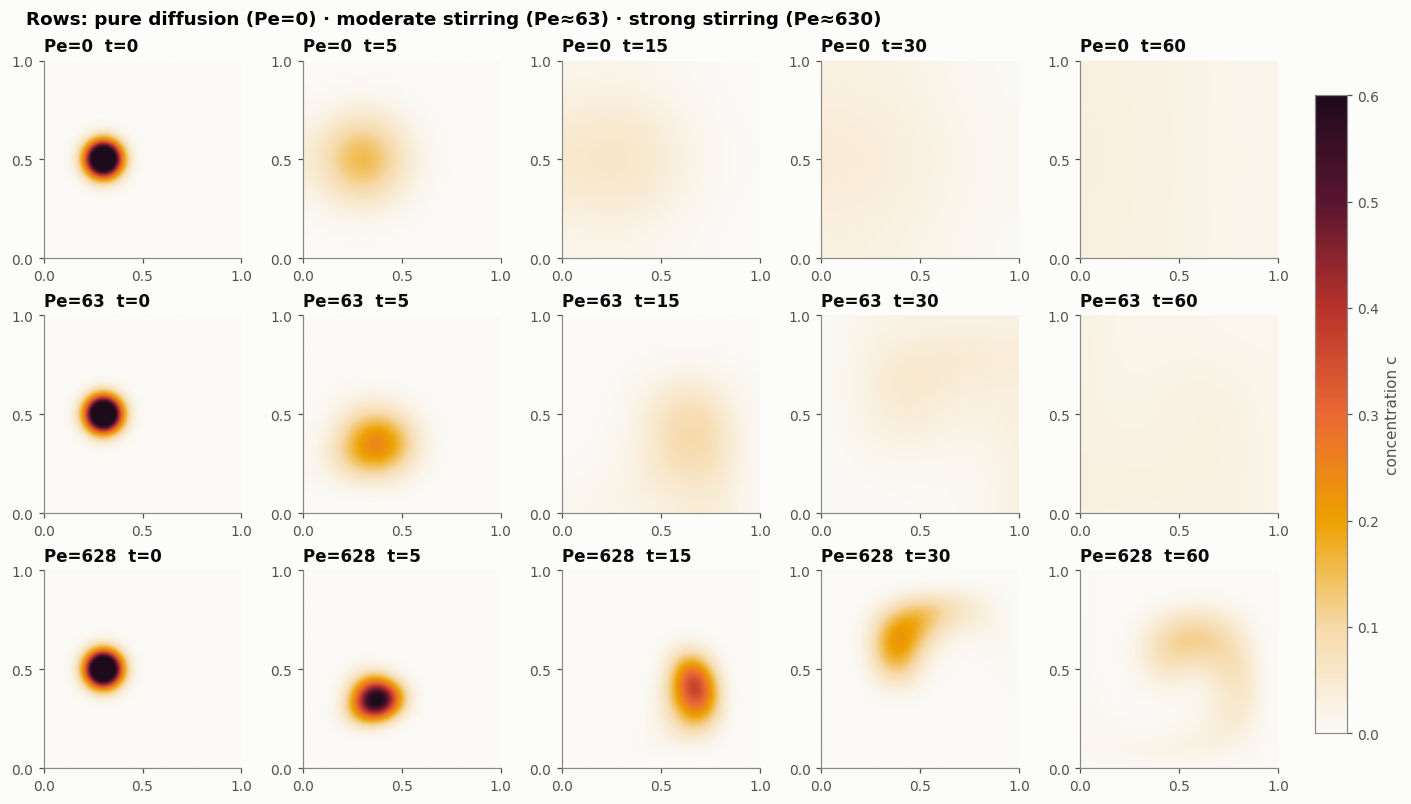

In [3]:
c0 = gaussian_blob(X, Y, 0.3, 0.5, width=0.06)
times = [0, 5, 15, 30, 60]
rows, labels = [], []
for kappa, amp in [(2e-3, 0.0), (1e-3, 0.02), (1e-4, 0.02)]:
    m = AdvDiff2D(n=96, kappa=kappa, flow_amplitude=amp)
    ts, C = m.simulate(c0, times[-1], save_every=1)
    pick = [np.argmin(abs(ts - tt)) for tt in times]
    rows += [C[p] for p in pick]
    pe = amp * np.pi / kappa
    labels += [f"Pe={pe:.0f}  t={tt}" for tt in times]

fig, axes = viz.snapshot_grid(rows, labels, ncols=5, vmin=0, vmax=0.6, label="concentration c",
                              size=2.4, suptitle="Rows: pure diffusion (Pe=0) · moderate stirring (Pe≈63) · strong stirring (Pe≈630)")
viz.save(fig, "05_peclet.png")
plt.show()

At high Pe the blob is stretched into a **spiral filament** before diffusion can smooth it.
A twin of such a flow needs denser sensors or smarter estimation; we revisit this in 06-07.

## 3. A leak: continuous source, probes, and arrival times
A leak starts at $(0.25, 0.3)$ at $t=0$ and stops at $t=20$. Four probes record concentration.

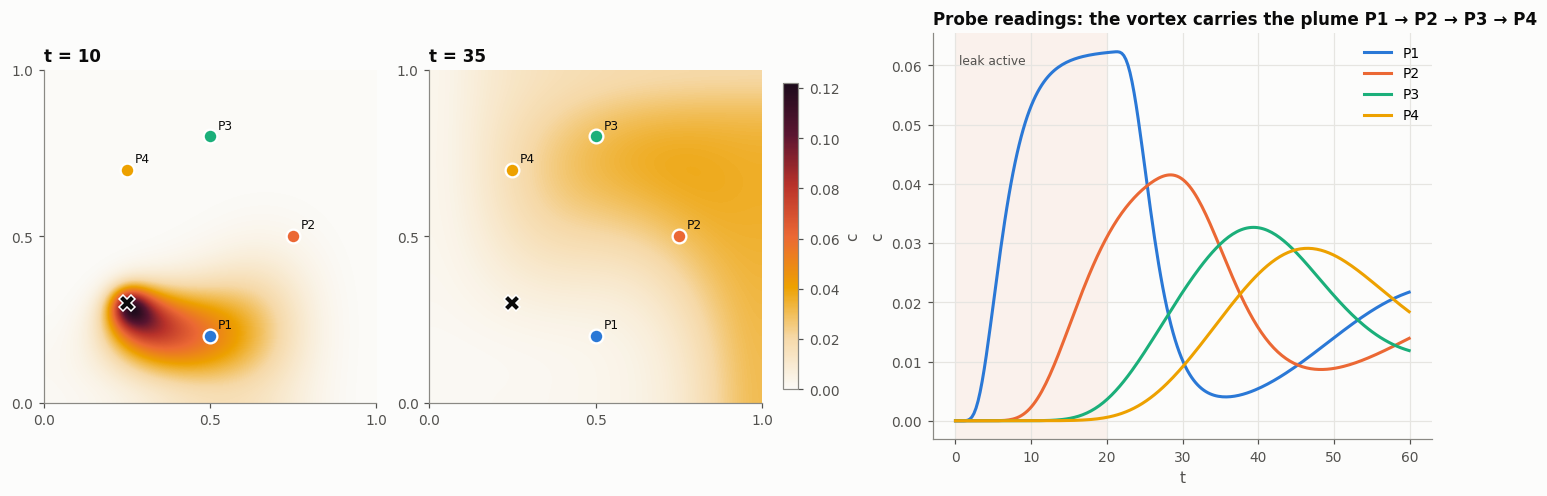

In [4]:
leak_xy = (0.25, 0.3)
leak = gaussian_blob(X, Y, *leak_xy, width=0.03, amp=0.15)
src = lambda t: leak if t < 20 else None
ts, C = tank.simulate(np.zeros_like(X), 60, source=src, save_every=20)

probes = {"P1": (0.5, 0.2), "P2": (0.75, 0.5), "P3": (0.5, 0.8), "P4": (0.25, 0.7)}
pidx = {k: (np.argmin(abs(tank.x - py)), np.argmin(abs(tank.x - px))) for k, (px, py) in probes.items()}

fig = plt.figure(figsize=(13, 4.4), constrained_layout=True)
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.5])
for j, tt in enumerate([10, 35]):
    ax = fig.add_subplot(gs[j])
    k = np.argmin(abs(ts - tt))
    viz.field(ax, C[k], vmin=0, vmax=C.max(), cbar=(j == 1), label="c", title=f"t = {ts[k]:.0f}")
    ax.plot(*leak_xy, "X", color=viz.INK, ms=10, mec="white")
    for i, (name, (px, py)) in enumerate(probes.items()):
        ax.plot(px, py, "o", color=viz.SERIES[i], ms=9, mec="white", mew=1.5)
        ax.annotate(name, (px, py), xytext=(5, 5), textcoords="offset points", fontsize=8, color=viz.INK)
ax = fig.add_subplot(gs[2])
for i, (name, (iy, ix)) in enumerate(pidx.items()):
    ax.plot(ts, C[:, iy, ix], color=viz.SERIES[i], label=name)
ax.axvspan(0, 20, color=viz.ORANGE, alpha=0.07, lw=0)
ax.text(0.5, ax.get_ylim()[1] * 0.92, "leak active", color=viz.INK2, fontsize=8)
ax.set(xlabel="t", ylabel="c", title="Probe readings: the vortex carries the plume P1 → P2 → P3 → P4")
ax.legend()
viz.save(fig, "05_leak_probes.png")
plt.show()

In [5]:
anim = viz.animate_2d([C[::2]], ts[::2], ["Leak in a stirred tank"], vlims=[(0, C.max())], size=4.2,
                      sensors=(np.array([p[0] for p in probes.values()]), np.array([p[1] for p in probes.values()])),
                      label="c")
HTML(anim.to_jshtml())

## 4. Mass balance
With zero-flux walls and no decay, total mass $\int c\,dA$ must grow exactly by what the leak injects.

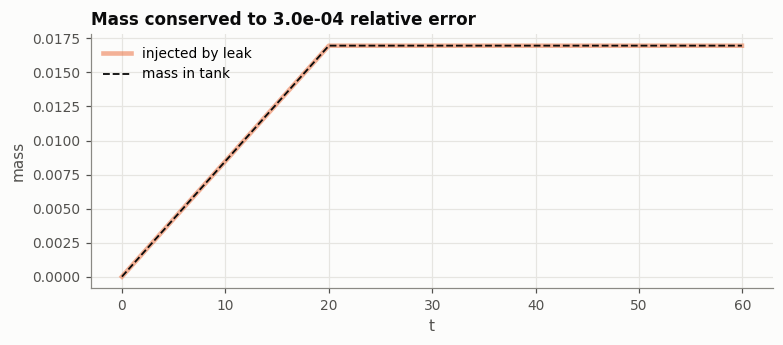

In [6]:
tfine, Cfine = tank.simulate(np.zeros_like(X), 60, source=src, save_every=5)
mass = Cfine.sum((1, 2)) * tank.dx**2
injected = np.minimum(tfine, 20) * leak.sum() * tank.dx**2

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(tfine, injected, color=viz.ORANGE, lw=3, alpha=0.5, label="injected by leak")
ax.plot(tfine, mass, color=viz.INK, lw=1.2, ls="--", label="mass in tank")
ax.set(xlabel="t", ylabel="mass", title=f"Mass conserved to {abs(mass[-1]-injected[-1])/injected[-1]:.1e} relative error")
ax.legend()
plt.show()

## 5. Expert note: numerical diffusion
First-order upwind advection adds an artificial diffusion $\kappa_{\text{num}}\approx U\Delta x/2$.
On a coarse grid it can exceed the physical $\kappa$: the model is *smoother* than reality. A twin
calibrated on a coarse grid will therefore learn a **too-small κ**, because calibration silently
compensates for discretisation error. Grid convergence studies are part of building a twin.

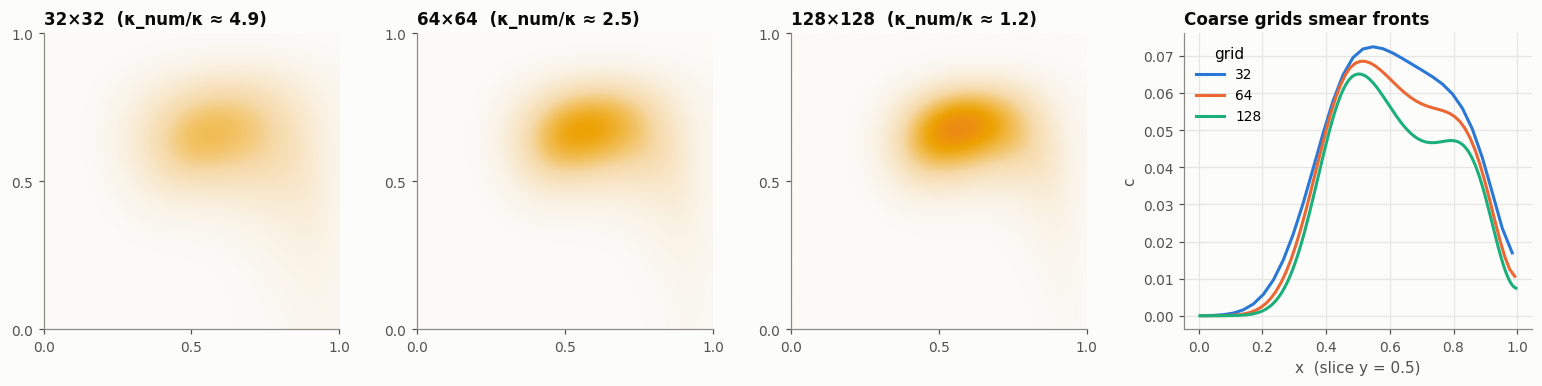

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), constrained_layout=True)
profiles = []
for ax, n in zip(axes[:3], [32, 64, 128]):
    m = AdvDiff2D(n=n, kappa=2e-4, flow_amplitude=0.02)
    c0n = gaussian_blob(m.X, m.Y, 0.3, 0.5, width=0.06)
    _, Cn = m.simulate(c0n, 25)
    viz.field(ax, Cn[-1], vmin=0, vmax=0.5, cbar=False, title=f"{n}×{n}  (κ_num/κ ≈ {0.02*np.pi*m.dx/2/2e-4:.1f})")
    j = n // 2
    profiles.append((m.x, Cn[-1][j]))
for i, (xx, p) in enumerate(profiles):
    axes[3].plot(xx, p, color=viz.SERIES[i], label=["32", "64", "128"][i])
axes[3].set(xlabel="x  (slice y = 0.5)", ylabel="c", title="Coarse grids smear fronts")
axes[3].legend(title="grid")
plt.show()

## Recap
* 2D transport fields are governed by the advection/diffusion balance (Péclet number).
* Visualise with snapshot grids (structure), probe series (what sensors see) and animations (dynamics).
* Validate with conservation laws; beware of numerical diffusion when calibrating.

**Next (06):** the twin doesn't know $\kappa$, the pump speed $a$, or the initial contamination.
We estimate all of them from 36 probes with the **ensemble Kalman filter**.